In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.api as sm
from scipy.stats import pearsonr

In [2]:
df = pd.read_excel('tabla_limpia_valores_reparada.xlsx', sheet_name='Sheet1')

In [3]:
print(f'Hay {df.shape[0]} filas y {df.shape[1]} columnas en el DataFrame.')
for name in df.columns:
    print(name)

Hay 8379 filas y 43 columnas en el DataFrame.
Fecha_hora
ML_REFI_NANO3
ML_REFI_SO4
ML_REFI_K
ML_REFI_CA
ML_REFI_MG
ML_REFI_KCLO4
ML_REFI_CLO4IC
Temp_Cristalización2_A3000
T Cry A3110
Temperatura ml refinación
Temperatura TK 6110
Temperatura TK6160
Agua de lavado Cf 3000
Agua de lavado Cf 6000
SSK NANO3
SSK CL
SSK SO4
SSK K
SSK MG
SSK CA
SSK KCLO4 IC
SSKCLO4 IC
Flujo SSK
Flujo SSKd
Agua de dilución
Purga_Recirculacion NaNO3
Purga_Recirculación SO4
Purga_Recirculacion K
Purga_Recirculación Ca
Purga_Recirculación Mg
Purga_Recirculación KClO4 IC
Purga_Recirculación ClO4 IC
Cristal sin refinar Cl
Cristal sin refinar SO4
Cristal sin refinar Ca
Cristal sin refinar Mg
Cristal sin refinar ClO4
Cristal Refinado Cl
Cristal Refinado SO4
Cristal Refinado Ca
Cristal Refinado Mg
Cristal refinado ClO4


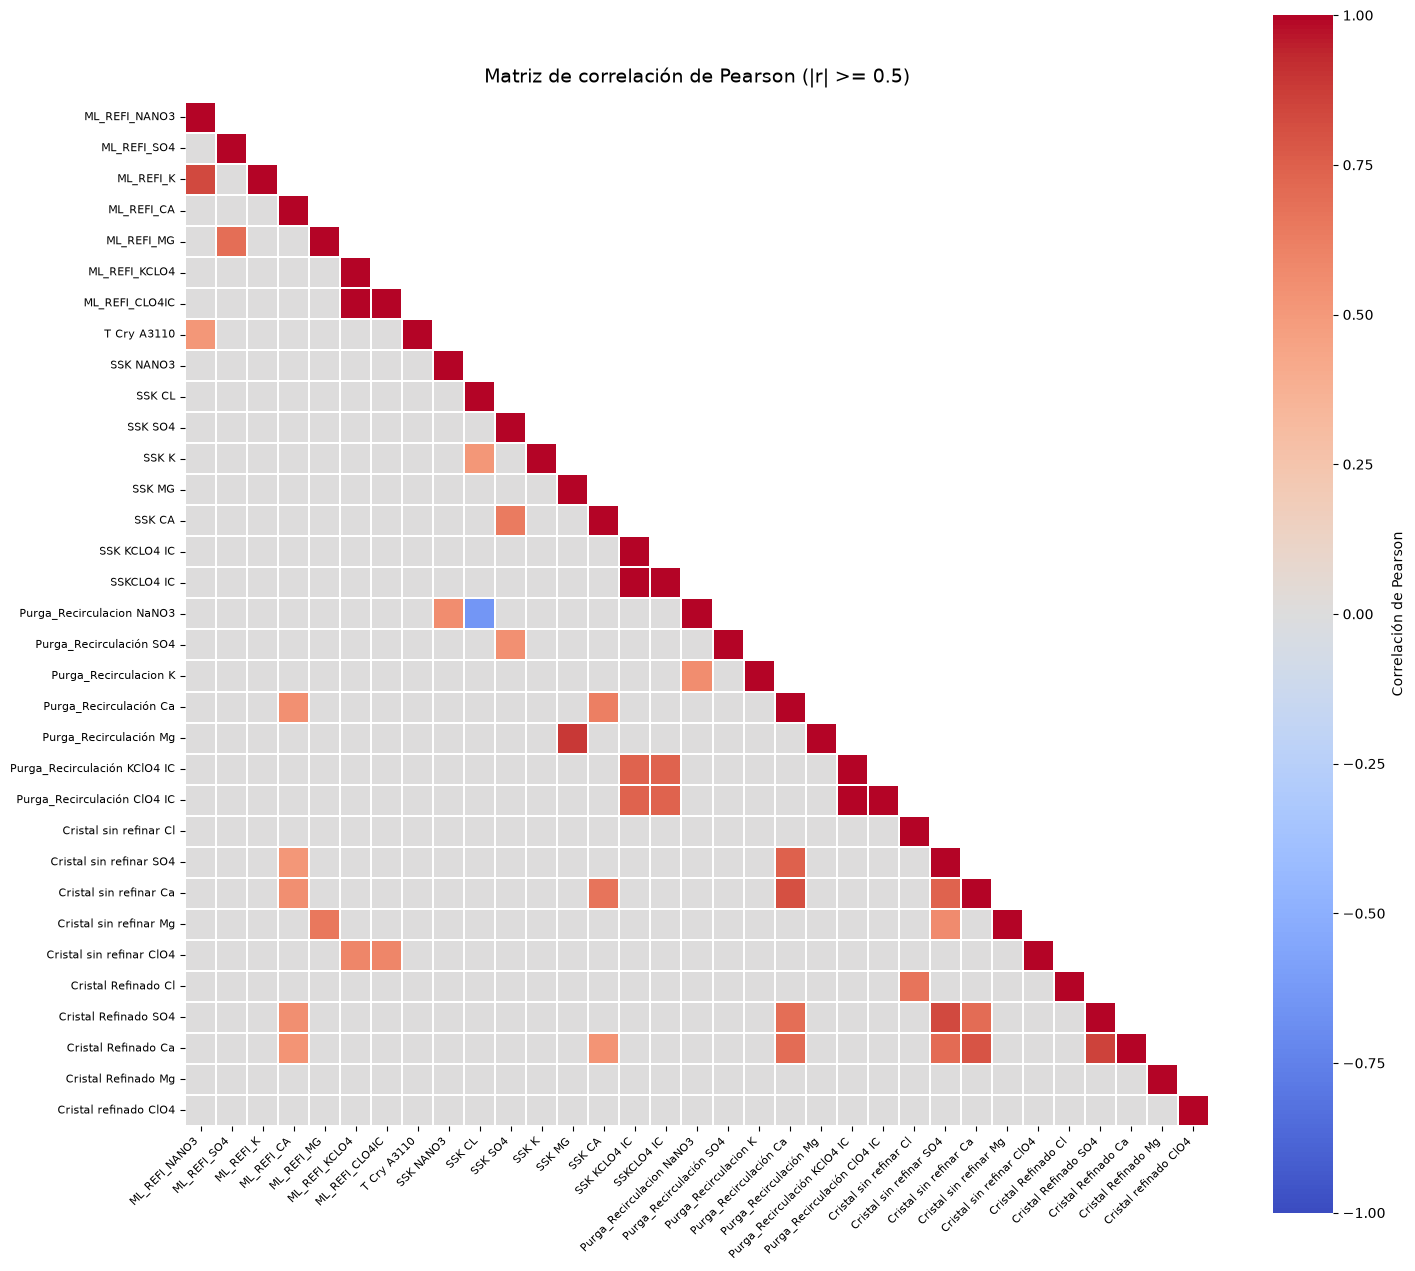

In [4]:
corr_df = df.corr( method='pearson', min_periods=1, numeric_only=True)

for col in corr_df.columns:
    corr_df[col] = corr_df[col].apply(lambda x: 0 if abs(x) < 0.5 else x)


# HEATMAP
n_features = len(corr_df.columns)
mask = np.triu(np.ones_like(corr_df, dtype=bool), k=1)
fig, ax = plt.subplots(
    figsize=(max(12, n_features * 0.45), max(10, n_features * 0.40))
)
sns.heatmap(
    corr_df,
    mask=mask,
    annot=False,
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.2,
    cbar_kws={'label': 'Correlación de Pearson'},
    ax=ax,
)
ax.set_title('Matriz de correlación de Pearson (|r| >= 0.5)', fontsize=14, pad=14)
ax.tick_params(axis='x', labelrotation=45, labelsize=8)
ax.tick_params(axis='y', labelrotation=0, labelsize=8)
plt.setp(ax.get_xticklabels(), ha='right')
fig.tight_layout()
plt.show()


In [37]:
corr_df.head()    

corr_df_important = pd.DataFrame(columns=['Pearson'])

for col in corr_df.columns:
    for row in corr_df.index:
        if abs(corr_df.loc[row, col]) >= 0.001 and row != col :
            if f'{row} - {col}' not in corr_df_important.index and f'{col} - {row}' not in corr_df_important.index:
                #print(f'La correlación entre {row} y {col} es {corr_df.loc[row, col]:.2f}')
                corr_df_important.loc[f'{row} - {col}'] = corr_df.loc[row, col]

corr_df_important = corr_df_important.sort_values(
    by='Pearson', key=lambda values: values.abs(), ascending=False
)

corr_df_important.to_excel('correlaciones_importantes.xlsx', index=True, header=['Pearson'])
print(corr_df_important.to_string())

                                                             Pearson
ML_REFI_CLO4IC - ML_REFI_KCLO4                              0.999547
Purga_Recirculación ClO4 IC - Purga_Recirculación KClO4 IC  0.997648
SSKCLO4 IC - SSK KCLO4 IC                                   0.997546
Purga_Recirculación Mg - SSK MG                             0.884298
Cristal Refinado Ca - Cristal Refinado SO4                  0.858219
ML_REFI_K - ML_REFI_NANO3                                   0.833352
Cristal Refinado SO4 - Cristal sin refinar SO4              0.832411
Cristal sin refinar Ca - Purga_Recirculación Ca             0.810892
Cristal Refinado Ca - Cristal sin refinar Ca                0.795150
Cristal sin refinar SO4 - Purga_Recirculación Ca            0.745063
Purga_Recirculación KClO4 IC - SSK KCLO4 IC                 0.738130
Purga_Recirculación ClO4 IC - SSK KCLO4 IC                  0.736526
Cristal sin refinar Ca - Cristal sin refinar SO4            0.736391
Purga_Recirculación KClO4 IC - SSK

In [6]:
all_columns = [
    'ML_REFI_NANO3',
    'ML_REFI_SO4',
    'ML_REFI_K',
    'ML_REFI_CA',
    'ML_REFI_MG',
    'ML_REFI_KCLO4',
    'ML_REFI_CLO4IC',
    'Temp_Cristalización2_A3000',
    'T Cry A3110',
    'Temperatura ml refinación',
    'Temperatura TK 6110',
    'Temperatura TK6160',
    'Agua de lavado Cf 3000',
    'Agua de lavado Cf 6000',
    'SSK NANO3',
    'SSK CL',
    'SSK SO4',
    'SSK K',
    'SSK MG',
    'SSK CA',
    'SSK KCLO4 IC',
    'Flujo SSK',
    'Flujo SSKd',
    'Agua de dilución',
    'Purga_Recirculacion NaNO3',
    'Purga_Recirculación SO4',
    'Purga_Recirculacion K',
    'Purga_Recirculación Ca',
    'Purga_Recirculación Mg',
    'Purga_Recirculación KClO4 IC',
    'Purga_Recirculación ClO4 IC',
    'Cristal sin refinar Cl',
    'Cristal sin refinar SO4',
    'Cristal sin refinar Ca',
    'Cristal sin refinar Mg',
    'Cristal sin refinar ClO4',
    'Cristal Refinado Cl',
    'Cristal Refinado SO4',
    'Cristal Refinado Ca',
    'Cristal Refinado Mg',
    'Cristal refinado ClO4'
]

cols_mg_clo4 = [
    'ML_REFI_MG',
    'ML_REFI_CLO4IC',
    'SSK MG',
    'SSK KCLO4 IC',
    'Purga_Recirculación Mg',
    'Purga_Recirculación ClO4 IC',
    'Cristal sin refinar Mg',
    'Cristal sin refinar ClO4',
    'Cristal Refinado Mg',
    'Cristal refinado ClO4',
]

cols_clo4 = ['ML_REFI_CLO4IC', 'SSK KCLO4 IC', 'Purga_Recirculación ClO4 IC', 'Cristal sin refinar ClO4', 'Cristal refinado ClO4']
cols_mg = [col for col in all_columns if 'mg' in col.lower()]
cols_so4 = [col for col in all_columns if 'so4' in col.lower() ]
cols_ca = [col for col in all_columns if 'ca' in col.lower() ]

In [7]:
print(cols_clo4)
print(cols_mg)
print(cols_so4)
print(cols_ca)

['ML_REFI_CLO4IC', 'SSK KCLO4 IC', 'Purga_Recirculación ClO4 IC', 'Cristal sin refinar ClO4', 'Cristal refinado ClO4']
['ML_REFI_MG', 'SSK MG', 'Purga_Recirculación Mg', 'Cristal sin refinar Mg', 'Cristal Refinado Mg']
['ML_REFI_SO4', 'SSK SO4', 'Purga_Recirculación SO4', 'Cristal sin refinar SO4', 'Cristal Refinado SO4']
['ML_REFI_CA', 'SSK CA', 'Purga_Recirculación Ca', 'Cristal sin refinar Ca', 'Cristal Refinado Ca']


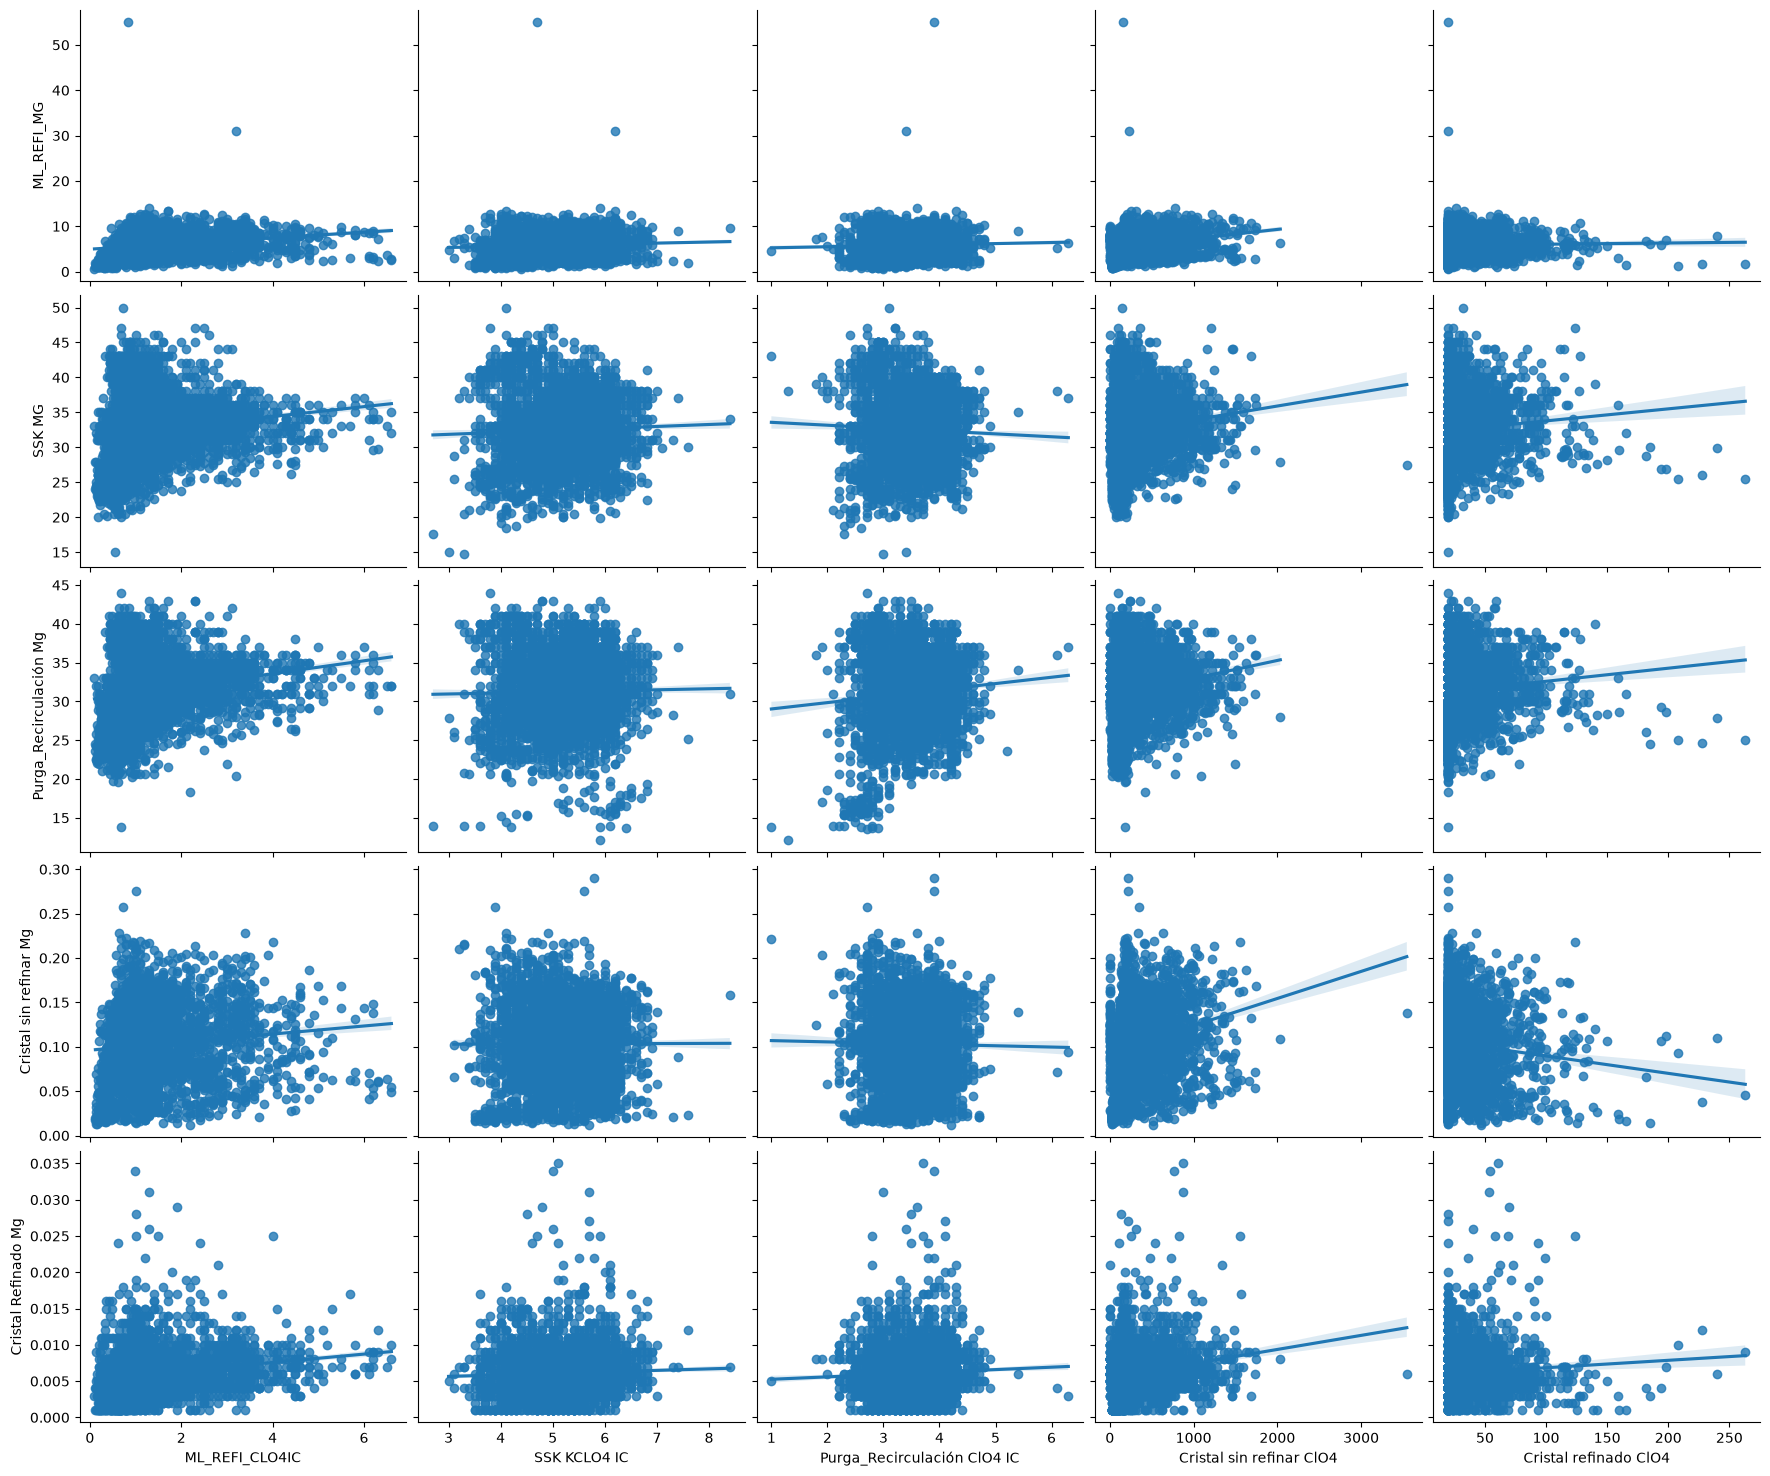

In [ ]:
g_clo4_mg = sns.pairplot(df, x_vars=cols_clo4, y_vars=cols_mg, height=3, aspect=1.2, kind='reg')



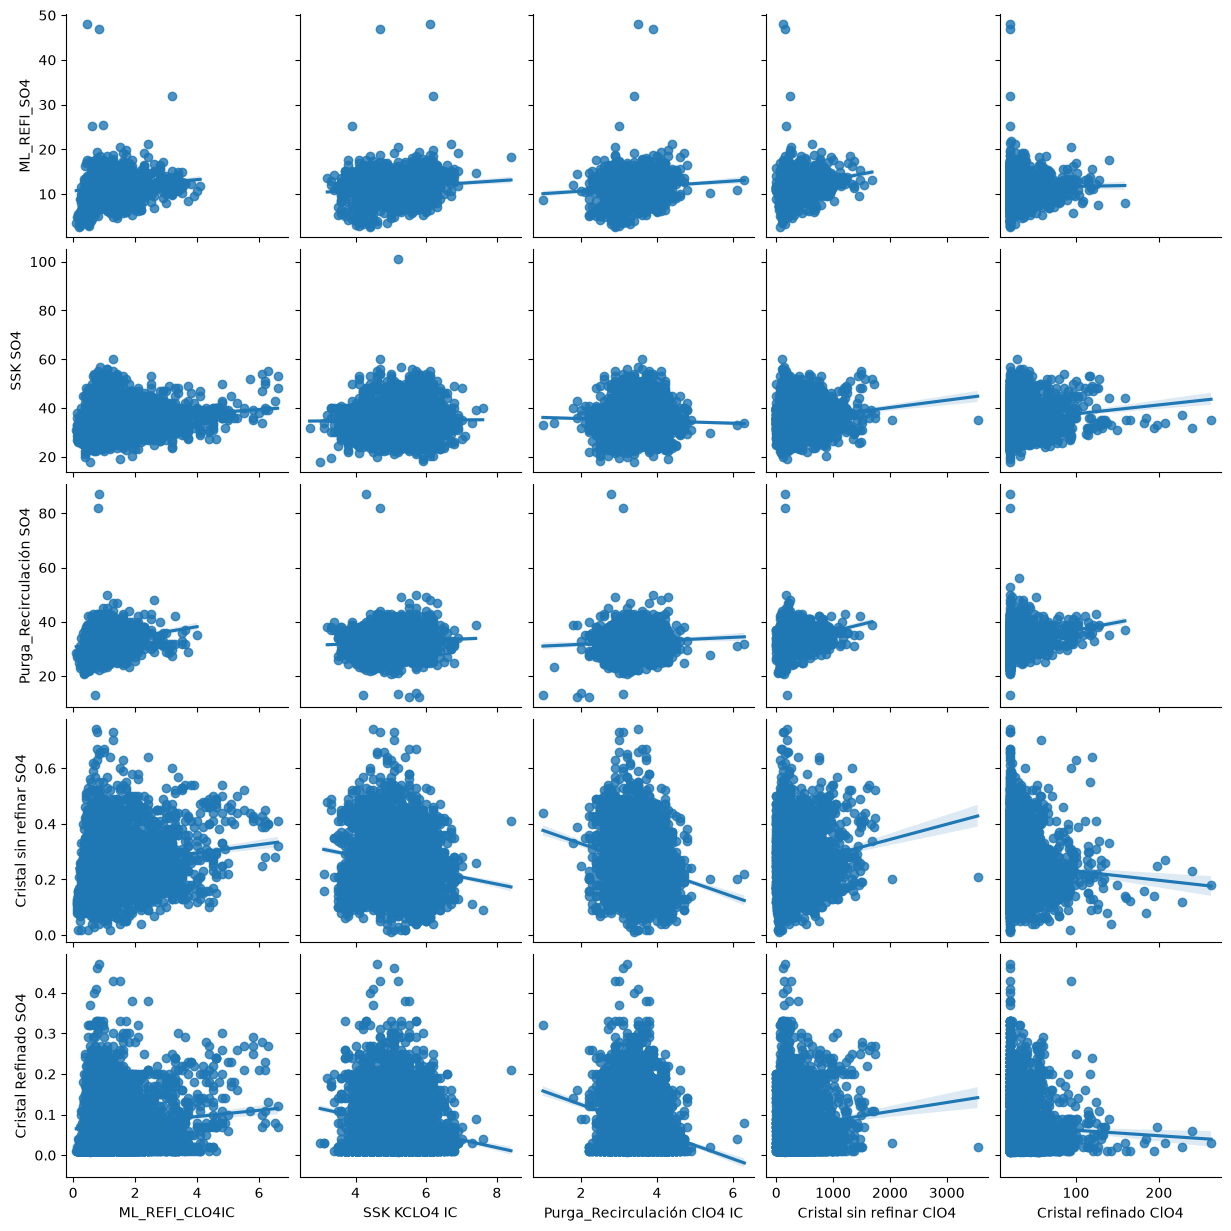

In [23]:
sns.pairplot(df, x_vars=cols_clo4, y_vars=cols_so4,kind='reg')


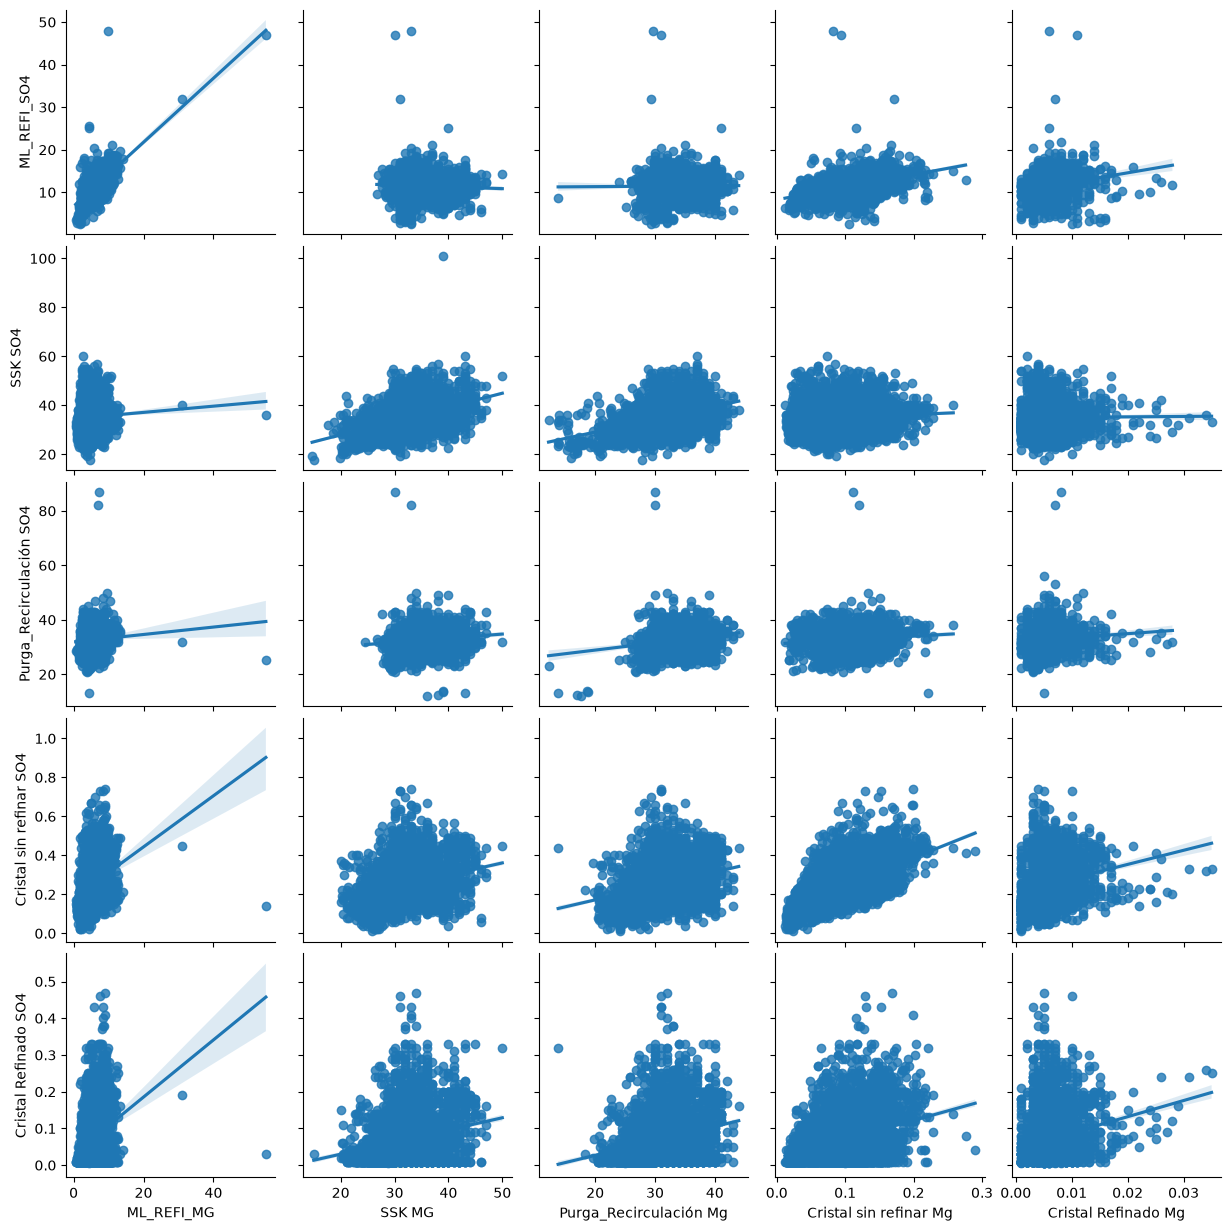

In [38]:
sns.pairplot(df, x_vars=cols_mg, y_vars=cols_so4,kind='reg')

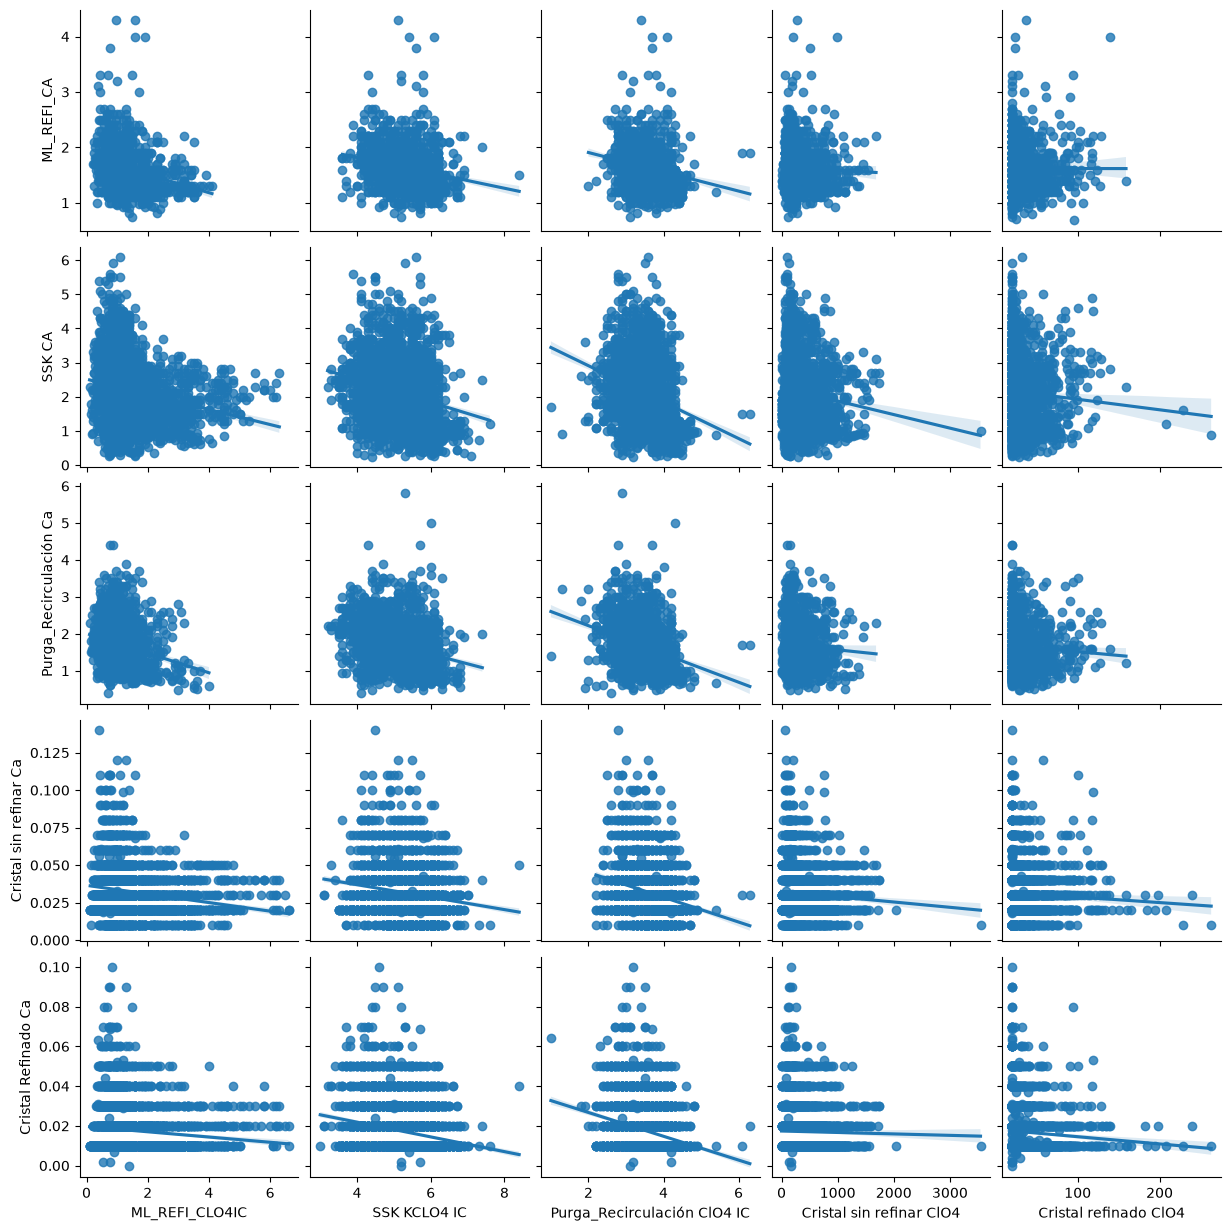

In [ ]:
sns.pairplot(df, x_vars=cols_clo4, y_vars=cols_ca,kind='reg')

## AJUSTE LINEAL

In [29]:
# y = df['Fecha_hora']

# X =  df.drop(axis=0, columns=['Fecha_hora'])

# X = sm.add_constant(X)

# modelo = sm.OLS(y, X, missing='drop').fit()
# #Cuantos filas se dropearon

# print(f"Filas usadas: {int(modelo.nobs)} de {len(df)}")
# print(f"Filas dropeadas por NaN: {len(df) - int(modelo.nobs)}")

In [39]:

# Choose a numeric response variable.
def calc_pvalues(columna_objetivo='Cristal sin refinar ClO4'):
    y_original = df[columna_objetivo]
    X_original = df.drop(columns=[columna_objetivo, 'Fecha_hora']).copy()

    # Coerce convierte los errores en NaN, ojo con tablas excel que usen n° con "," como separador
    y = pd.to_numeric(y_original, errors='coerce')
    X = X_original.apply(pd.to_numeric, errors='coerce')
    
    invalid_values = {}
    for column in X_original.columns:
        invalid = X_original[column].notna() & X[column].isna()
        if invalid.any():
            invalid_values[column] = X_original.loc[invalid, column].value_counts().to_dict()
    
    if invalid_values:
        print('Non-numeric predictor values treated as missing:')
        for column, values in invalid_values.items():
            print(f'  {column}: {values}')
    
    invalid_target = y_original.notna() & y.isna()
    if invalid_target.any():
        print(f'Target values treated as missing: {int(invalid_target.sum())}')
    
    # OLS requires complete numeric rows; drop and count them explicitly.
    model_data = pd.concat([y.rename(columna_objetivo), X], axis=1).dropna()
    if model_data.empty:
        raise ValueError('No complete numeric rows are available for the OLS model.')
    
    y_model = model_data.pop(columna_objetivo)
    X_model = sm.add_constant(model_data, has_constant='add')
    modelo = sm.OLS(y_model, X_model).fit()

    print(modelo.summary())
    
    print(f'Rows used: {int(modelo.nobs)} of {len(df)}')
    print(f'Rows dropped due to missing/invalid values: {len(df) - int(modelo.nobs)}')
    
    p_valores = modelo.pvalues.sort_values()
    return p_valores

In [40]:
columna_objetivo = 'Cristal sin refinar ClO4'

p_valores = calc_pvalues(columna_objetivo)
print(p_valores[p_valores<=0.01])

Non-numeric predictor values treated as missing:
  Temp_Cristalización2_A3000: {'Null': 16}
  Temperatura ml refinación: {'Null': 34}
  Temperatura TK 6110: {'Null': 95}
  Temperatura TK6160: {'Null': 95}
  Agua de lavado Cf 3000: {'Null': 16}
  Agua de lavado Cf 6000: {'Null': 97}
  Flujo SSK: {'La hora especificada no es válida.': 1}
  Flujo SSKd: {'La hora especificada no es válida.': 1}
  Agua de dilución: {'La hora especificada no es válida.': 1}
                               OLS Regression Results                               
Dep. Variable:     Cristal sin refinar ClO4   R-squared:                       0.578
Model:                                  OLS   Adj. R-squared:                  0.560
Method:                       Least Squares   F-statistic:                     32.44
Date:                      Wed, 25 Nov 2026   Prob (F-statistic):          2.22e-152
Time:                              16:07:45   Log-Likelihood:                -6522.0
No. Observations:                 

In [45]:
columna_objetivo = 'Cristal refinado ClO4'

p_valores = calc_pvalues(columna_objetivo)
print(p_valores[p_valores<=0.01])

Non-numeric predictor values treated as missing:
  Temp_Cristalización2_A3000: {'Null': 16}
  Temperatura ml refinación: {'Null': 34}
  Temperatura TK 6110: {'Null': 95}
  Temperatura TK6160: {'Null': 95}
  Agua de lavado Cf 3000: {'Null': 16}
  Agua de lavado Cf 6000: {'Null': 97}
  Flujo SSK: {'La hora especificada no es válida.': 1}
  Flujo SSKd: {'La hora especificada no es válida.': 1}
  Agua de dilución: {'La hora especificada no es válida.': 1}
                              OLS Regression Results                             
Dep. Variable:     Cristal refinado ClO4   R-squared:                       0.556
Model:                               OLS   Adj. R-squared:                  0.537
Method:                    Least Squares   F-statistic:                     29.59
Date:                   Wed, 25 Nov 2026   Prob (F-statistic):          9.55e-142
Time:                           16:20:13   Log-Likelihood:                -4060.8
No. Observations:                   1012   AIC:     

In [44]:
columna_objetivo = 'Cristal Refinado Mg'

p_valores = calc_pvalues(columna_objetivo)
print(p_valores[p_valores<=0.01])

Non-numeric predictor values treated as missing:
  Temp_Cristalización2_A3000: {'Null': 16}
  Temperatura ml refinación: {'Null': 34}
  Temperatura TK 6110: {'Null': 95}
  Temperatura TK6160: {'Null': 95}
  Agua de lavado Cf 3000: {'Null': 16}
  Agua de lavado Cf 6000: {'Null': 97}
  Flujo SSK: {'La hora especificada no es válida.': 1}
  Flujo SSKd: {'La hora especificada no es válida.': 1}
  Agua de dilución: {'La hora especificada no es válida.': 1}
                             OLS Regression Results                            
Dep. Variable:     Cristal Refinado Mg   R-squared:                       0.429
Model:                             OLS   Adj. R-squared:                  0.405
Method:                  Least Squares   F-statistic:                     17.79
Date:                 Wed, 25 Nov 2026   Prob (F-statistic):           3.83e-91
Time:                         16:19:20   Log-Likelihood:                 4842.4
No. Observations:                 1012   AIC:                   